ANALISIS GIS FASILITAS KESEHATAN
Studi Kasus: Kota Bengkulu
Sumber Data: OpenStreetMap

[1] Mengambil jaringan jalan...
Pengambilan jaringan jalan (percobaan 1/3)
Jumlah simpul: 4269
Jumlah ruas: 10087

[2] Mengambil fasilitas kesehatan...
Pengambilan fasilitas kesehatan (percobaan 1/3)
Jumlah fasilitas: 10
jenis
clinic      5
hospital    4
doctors     1
Name: count, dtype: int64

[3] Mengambil bangunan hunian...
Pengambilan bangunan hunian (percobaan 1/3)
Bangunan terpetakan: 80
Bangunan dianalisis: 80

[4] Memetakan lokasi ke jaringan jalan...

[5] Menghitung jarak jaringan jalan...

[6] Menghitung statistik...
-------------------------------------------------------
Jumlah fasilitas     : 10
Bangunan dianalisis  : 3
Rata-rata jarak      : 0.20 km
Median jarak         : 0.20 km
Jarak minimum        : 0.20 km
Jarak maksimum       : 0.21 km
Di luar ambang       : 0
Persentase           : 0.00%
-------------------------------------------------------

10 bangunan dengan jarak terbesar:


,id_bangunan,fasilitas_terdekat,jarak_km,kategori
2,B040,Puskesmas Pembantu,0.205,Dalam ambang
0,B031,Puskesmas Pembantu,0.202,Dalam ambang
1,B035,Puskesmas Pembantu,0.202,Dalam ambang



[7] Membuat grafik...


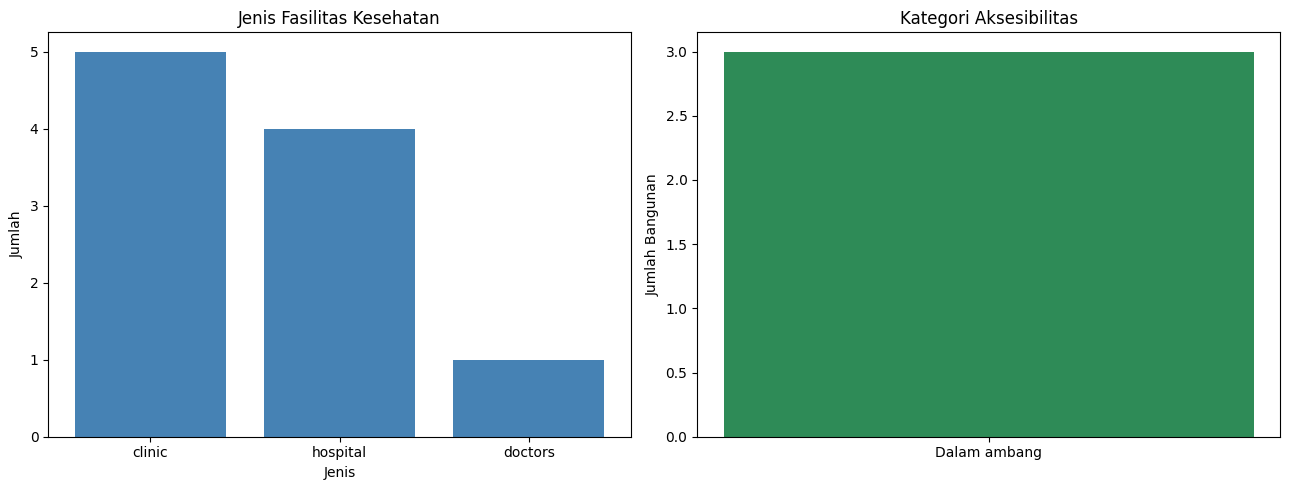


[8] Membuat peta interaktif...

[9] Menampilkan contoh rute...



[10] Menyimpan hasil...

KESIMPULAN ANALISIS GIS
Ditemukan 10 fasilitas kesehatan dalam area pengamatan.
Sebanyak 3 bangunan hunian berhasil dianalisis.
Rata-rata jarak jaringan jalan menuju fasilitas terdekat adalah 0.20 km.
Terdapat 0 bangunan (0.00%) dengan jarak lebih dari 3.0 km.

Catatan: Hasil menggunakan data OSM dan jaringan jalan tidak berarah. Jarak dihitung antarsimpul jalan terdekat, tanpa tambahan jarak akses dari bangunan ke jalan atau dari jalan ke pintu fasilitas.

File tersimpan di: /content/hasil_gis_bengkulu
- bangunan_hunian.csv
- fasilitas_kesehatan.csv
- grafik_gis.png
- hasil_analisis_gis.csv
- peta_aksesibilitas.html
- ringkasan_gis.csv

ANALISIS SELESAI


In [2]:
import sys
import subprocess
import importlib.util
import os
import time
import warnings
from datetime import datetime, timezone

warnings.filterwarnings("ignore", category=FutureWarning)

# ==============================================================
# 1. INSTALASI LIBRARY
# ==============================================================

libraries = {
    "osmnx": "osmnx",
    "geopandas": "geopandas",
    "networkx": "networkx",
    "folium": "folium",
    "matplotlib": "matplotlib",
    "pandas": "pandas",
    "numpy": "numpy",
    "shapely": "shapely"
}

for module, package in libraries.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", "-q", package
        ])

import osmnx as ox
import geopandas as gpd
import networkx as nx
import folium
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from shapely.geometry import Point
from IPython.display import display

# ==============================================================
# 2. KONFIGURASI
# ==============================================================

WILAYAH = "Bengkulu City, Bengkulu, Indonesia"

OUTPUT = "/content/hasil_gis_bengkulu"
os.makedirs(OUTPUT, exist_ok=True)

MAX_BANGUNAN = 100
SEED = 42
AMBANG_KM = 3.0

LAT_PUSAT = -3.8004
LON_PUSAT = 102.2655
RADIUS_METER = 3500

MAX_RETRY = 3

ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(
    OUTPUT, "cache_osm"
)
ox.settings.log_console = False
ox.settings.requests_timeout = 300

# ==============================================================
# 3. FUNGSI RETRY PERMINTAAN OSM
# ==============================================================

def retry_osm(function, description, attempts=MAX_RETRY):
    """
    Mengulangi permintaan ketika layanan OSM gagal.
    Tidak membuat data pengganti atau data sintetis.
    """

    for attempt in range(1, attempts + 1):
        try:
            print(
                f"{description} "
                f"(percobaan {attempt}/{attempts})"
            )

            result = function()

            if result is None:
                raise RuntimeError("Respons kosong.")

            return result

        except Exception as error:
            print(
                f"Gagal: {type(error).__name__}: "
                f"{str(error)[:250]}"
            )

            if attempt == attempts:
                raise RuntimeError(
                    f"{description} gagal setelah "
                    f"{attempts} percobaan. "
                    "Periksa koneksi atau layanan OSM."
                ) from error

            time.sleep(5 * attempt)


print("=" * 65)
print("ANALISIS GIS FASILITAS KESEHATAN")
print("Studi Kasus: Kota Bengkulu")
print("Sumber Data: OpenStreetMap")
print("=" * 65)

# ==============================================================
# 4. MENGAMBIL JARINGAN JALAN NYATA
# ==============================================================

print("\n[1] Mengambil jaringan jalan...")

G = retry_osm(
    lambda: ox.graph_from_point(
        (LAT_PUSAT, LON_PUSAT),
        dist=RADIUS_METER,
        network_type="drive",
        simplify=True,
        retain_all=False
    ),
    "Pengambilan jaringan jalan"
)

if len(G.nodes) == 0:
    raise RuntimeError("Jaringan jalan kosong.")

print("Jumlah simpul:", len(G.nodes))
print("Jumlah ruas:", len(G.edges))


G = ox.convert.to_undirected(G)

G_proj = ox.project_graph(G)

# ==============================================================
# 5. MENGAMBIL FASILITAS KESEHATAN
# ==============================================================

print("\n[2] Mengambil fasilitas kesehatan...")

tags_kesehatan = {
    "amenity": [
        "hospital",
        "clinic",
        "doctors"
    ]
}

fasilitas_raw = retry_osm(
    lambda: ox.features_from_point(
        (LAT_PUSAT, LON_PUSAT),
        tags=tags_kesehatan,
        dist=RADIUS_METER
    ),
    "Pengambilan fasilitas kesehatan"
)

if fasilitas_raw.empty:
    raise RuntimeError(
        "Tidak ditemukan fasilitas kesehatan "
        "pada area pengamatan."
    )

fasilitas_raw = fasilitas_raw.reset_index()

for col in ["name", "amenity"]:
    if col not in fasilitas_raw.columns:
        fasilitas_raw[col] = None

fasilitas = gpd.GeoDataFrame(
    fasilitas_raw[
        ["name", "amenity", "geometry"]
    ].copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

fasilitas = fasilitas[
    fasilitas.geometry.notna()
].copy()

fasilitas["geometry"] = (
    fasilitas.geometry.representative_point()
)

fasilitas["nama"] = (
    fasilitas["name"]
    .fillna("Nama tidak tersedia")
    .astype(str)
)

fasilitas["jenis"] = (
    fasilitas["amenity"]
    .fillna("Tidak diketahui")
    .astype(str)
)

fasilitas = fasilitas.reset_index(drop=True)

if fasilitas.empty:
    raise RuntimeError(
        "Tidak ada fasilitas kesehatan valid."
    )

print("Jumlah fasilitas:", len(fasilitas))
print(fasilitas["jenis"].value_counts())

# ==============================================================
# 6. MENGAMBIL BANGUNAN HUNIAN NYATA
# ==============================================================

print("\n[3] Mengambil bangunan hunian...")

tags_bangunan = {
    "building": [
        "residential",
        "house",
        "apartments",
        "detached"
    ]
}

bangunan_raw = retry_osm(
    lambda: ox.features_from_point(
        (LAT_PUSAT, LON_PUSAT),
        tags=tags_bangunan,
        dist=RADIUS_METER
    ),
    "Pengambilan bangunan hunian"
)

if bangunan_raw.empty:
    raise RuntimeError(
        "Tidak ditemukan bangunan hunian "
        "dengan tag yang dipilih."
    )

bangunan_raw = bangunan_raw.reset_index()

bangunan = gpd.GeoDataFrame(
    bangunan_raw[["geometry"]].copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

bangunan = bangunan[
    bangunan.geometry.notna()
].copy()


bangunan = bangunan.drop_duplicates(
    subset="geometry"
)

bangunan["geometry"] = (
    bangunan.geometry.representative_point()
)

jumlah_bangunan_asli = len(bangunan)

if jumlah_bangunan_asli == 0:
    raise RuntimeError(
        "Tidak ada geometri bangunan yang valid."
    )

if len(bangunan) > MAX_BANGUNAN:
    bangunan = bangunan.sample(
        n=MAX_BANGUNAN,
        random_state=SEED
    )

bangunan = bangunan.reset_index(drop=True)

bangunan["id_bangunan"] = [
    f"B{i+1:03d}"
    for i in range(len(bangunan))
]

print("Bangunan terpetakan:", jumlah_bangunan_asli)
print("Bangunan dianalisis:", len(bangunan))

# ==============================================================
# 7. MEMETAKAN LOKASI KE SIMPUL JALAN
# ==============================================================

print("\n[4] Memetakan lokasi ke jaringan jalan...")

fasilitas_proj = fasilitas.to_crs(
    G_proj.graph["crs"]
)

bangunan_proj = bangunan.to_crs(
    G_proj.graph["crs"]
)

fasilitas["node"] = ox.distance.nearest_nodes(
    G_proj,
    X=fasilitas_proj.geometry.x.to_numpy(),
    Y=fasilitas_proj.geometry.y.to_numpy()
)

bangunan["node"] = ox.distance.nearest_nodes(
    G_proj,
    X=bangunan_proj.geometry.x.to_numpy(),
    Y=bangunan_proj.geometry.y.to_numpy()
)

# ==============================================================
# 8. ALGORITMA DIJKSTRA
# ==============================================================

print("\n[5] Menghitung jarak jaringan jalan...")

source_nodes = list(
    set(fasilitas["node"].tolist())
)

jarak_node, jalur_node = nx.multi_source_dijkstra(
    G_proj,
    sources=source_nodes,
    weight="length"
)

# Pemetaan simpul ke fasilitas
node_fasilitas = {}

for idx, row in fasilitas.iterrows():
    node = row["node"]

    if node not in node_fasilitas:
        node_fasilitas[node] = idx

hasil_rows = []

for _, row in bangunan.iterrows():

    node = row["node"]

    if node not in jarak_node:
        continue

    jarak_meter = jarak_node[node]
    jalur = jalur_node[node]

    sumber = jalur[0]

    idx_fasilitas = node_fasilitas[sumber]
    fasilitas_tujuan = fasilitas.loc[idx_fasilitas]

    hasil_rows.append({
        "id_bangunan": row["id_bangunan"],
        "latitude": row.geometry.y,
        "longitude": row.geometry.x,
        "fasilitas_terdekat": fasilitas_tujuan["nama"],
        "jenis_fasilitas": fasilitas_tujuan["jenis"],
        "jarak_km": jarak_meter / 1000,
        "node_bangunan": node,
        "node_fasilitas": sumber
    })

hasil = pd.DataFrame(hasil_rows)

if hasil.empty:
    raise RuntimeError(
        "Tidak ada bangunan yang terhubung "
        "ke jaringan jalan."
    )

hasil["kategori"] = np.where(
    hasil["jarak_km"] <= AMBANG_KM,
    "Dalam ambang",
    "Di luar ambang"
)

# ==============================================================
# 9. STATISTIK
# ==============================================================

print("\n[6] Menghitung statistik...")

rata = hasil["jarak_km"].mean()
median = hasil["jarak_km"].median()
minimum = hasil["jarak_km"].min()
maksimum = hasil["jarak_km"].max()

luar_ambang = (
    hasil["kategori"] == "Di luar ambang"
).sum()

persentase = (
    luar_ambang / len(hasil) * 100
)

print("-" * 55)
print(f"Jumlah fasilitas     : {len(fasilitas)}")
print(f"Bangunan dianalisis  : {len(hasil)}")
print(f"Rata-rata jarak      : {rata:.2f} km")
print(f"Median jarak         : {median:.2f} km")
print(f"Jarak minimum        : {minimum:.2f} km")
print(f"Jarak maksimum       : {maksimum:.2f} km")
print(f"Di luar ambang       : {luar_ambang}")
print(f"Persentase           : {persentase:.2f}%")
print("-" * 55)

print("\n10 bangunan dengan jarak terbesar:")

display(
    hasil.sort_values(
        "jarak_km",
        ascending=False
    )[
        [
            "id_bangunan",
            "fasilitas_terdekat",
            "jarak_km",
            "kategori"
        ]
    ].head(10).round(3)
)

# ==============================================================
# 10. VISUALISASI GRAFIK
# ==============================================================

print("\n[7] Membuat grafik...")

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5)
)

jenis_count = fasilitas["jenis"].value_counts()

axes[0].bar(
    jenis_count.index,
    jenis_count.values,
    color="steelblue"
)

axes[0].set_title("Jenis Fasilitas Kesehatan")
axes[0].set_xlabel("Jenis")
axes[0].set_ylabel("Jumlah")

kategori_count = hasil["kategori"].value_counts()

axes[1].bar(
    kategori_count.index,
    kategori_count.values,
    color=[
        "seagreen" if k == "Dalam ambang"
        else "tomato"
        for k in kategori_count.index
    ]
)

axes[1].set_title("Kategori Aksesibilitas")
axes[1].set_ylabel("Jumlah Bangunan")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT, "grafik_gis.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# ==============================================================
# 11. PETA INTERAKTIF
# ==============================================================

print("\n[8] Membuat peta interaktif...")

peta = folium.Map(
    location=[LAT_PUSAT, LON_PUSAT],
    zoom_start=13,
    tiles="OpenStreetMap"
)

# Layer fasilitas
layer_fasilitas = folium.FeatureGroup(
    name="Fasilitas Kesehatan"
)

for _, row in fasilitas.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=6,
        color="blue",
        fill=True,
        fill_opacity=0.9,
        popup=folium.Popup(
            f"<b>{row['nama']}</b><br>"
            f"Jenis: {row['jenis']}",
            max_width=250
        )
    ).add_to(layer_fasilitas)

layer_fasilitas.add_to(peta)

# Layer bangunan
layer_bangunan = folium.FeatureGroup(
    name="Bangunan Hunian"
)

for _, row in hasil.iterrows():

    warna = (
        "green"
        if row["kategori"] == "Dalam ambang"
        else "red"
    )

    popup = (
        f"<b>{row['id_bangunan']}</b><br>"
        f"Fasilitas: {row['fasilitas_terdekat']}<br>"
        f"Jarak jaringan: {row['jarak_km']:.2f} km<br>"
        f"Kategori: {row['kategori']}"
    )

    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],
        radius=5,
        color=warna,
        fill=True,
        fill_color=warna,
        fill_opacity=0.8,
        popup=folium.Popup(
            popup, max_width=300
        )
    ).add_to(layer_bangunan)

layer_bangunan.add_to(peta)

# ==============================================================
# 12. VISUALISASI RUTE TERPENDEK
# ==============================================================

print("\n[9] Menampilkan contoh rute...")

layer_rute = folium.FeatureGroup(
    name="Contoh Rute Jaringan Jalan"
)

contoh = hasil.nlargest(
    10, "jarak_km"
)

for _, row in contoh.iterrows():

    node = row["node_bangunan"]

    if node not in jalur_node:
        continue

    route = jalur_node[node]

    points = [
        Point(
            G_proj.nodes[n]["x"],
            G_proj.nodes[n]["y"]
        )
        for n in route
    ]

    route_geo = gpd.GeoSeries(
        points,
        crs=G_proj.graph["crs"]
    ).to_crs("EPSG:4326")

    coordinates = [
        [p.y, p.x]
        for p in route_geo
    ]

    if len(coordinates) >= 2:
        folium.PolyLine(
            locations=coordinates,
            color="purple",
            weight=3,
            opacity=0.7,
            tooltip=(
                f"{row['id_bangunan']}: "
                f"{row['jarak_km']:.2f} km"
            )
        ).add_to(layer_rute)

layer_rute.add_to(peta)

folium.LayerControl().add_to(peta)

peta.save(
    os.path.join(
        OUTPUT,
        "peta_aksesibilitas.html"
    )
)

display(peta)

# ==============================================================
# 13. EKSPOR DATA CSV
# ==============================================================

print("\n[10] Menyimpan hasil...")

fasilitas_csv = fasilitas.copy()

fasilitas_csv["latitude"] = (
    fasilitas_csv.geometry.y
)

fasilitas_csv["longitude"] = (
    fasilitas_csv.geometry.x
)

fasilitas_csv[
    ["nama", "jenis", "latitude", "longitude"]
].to_csv(
    os.path.join(
        OUTPUT, "fasilitas_kesehatan.csv"
    ),
    index=False
)

bangunan_csv = bangunan.copy()

bangunan_csv["latitude"] = (
    bangunan_csv.geometry.y
)

bangunan_csv["longitude"] = (
    bangunan_csv.geometry.x
)

bangunan_csv[
    ["id_bangunan", "latitude", "longitude"]
].to_csv(
    os.path.join(
        OUTPUT, "bangunan_hunian.csv"
    ),
    index=False
)

hasil.drop(
    columns=["node_bangunan", "node_fasilitas"]
).to_csv(
    os.path.join(
        OUTPUT, "hasil_analisis_gis.csv"
    ),
    index=False
)

ringkasan = pd.DataFrame([{
    "wilayah": WILAYAH,
    "jumlah_fasilitas": len(fasilitas),
    "bangunan_terpetakan": jumlah_bangunan_asli,
    "bangunan_dianalisis": len(hasil),
    "rata_rata_jarak_km": rata,
    "median_jarak_km": median,
    "jarak_minimum_km": minimum,
    "jarak_maksimum_km": maksimum,
    "jumlah_di_luar_ambang": int(luar_ambang),
    "persentase_di_luar_ambang": persentase,
    "tanggal_analisis_utc": datetime.now(
        timezone.utc
    ).isoformat()
}])

ringkasan.to_csv(
    os.path.join(
        OUTPUT, "ringkasan_gis.csv"
    ),
    index=False
)

# ==============================================================
# 14. KESIMPULAN OTOMATIS
# ==============================================================

print("\n" + "=" * 65)
print("KESIMPULAN ANALISIS GIS")
print("=" * 65)

print(
    f"Ditemukan {len(fasilitas)} fasilitas kesehatan "
    f"dalam area pengamatan."
)

print(
    f"Sebanyak {len(hasil)} bangunan hunian "
    f"berhasil dianalisis."
)

print(
    f"Rata-rata jarak jaringan jalan menuju "
    f"fasilitas terdekat adalah {rata:.2f} km."
)

print(
    f"Terdapat {luar_ambang} bangunan "
    f"({persentase:.2f}%) dengan jarak "
    f"lebih dari {AMBANG_KM} km."
)

print(
    "\nCatatan: Hasil menggunakan data OSM "
    "dan jaringan jalan tidak berarah. "
    "Jarak dihitung antarsimpul jalan terdekat, "
    "tanpa tambahan jarak akses dari bangunan "
    "ke jalan atau dari jalan ke pintu fasilitas."
)

print("\nFile tersimpan di:", OUTPUT)

for filename in sorted(os.listdir(OUTPUT)):
    if os.path.isfile(os.path.join(OUTPUT, filename)):
        print("-", filename)

print("\nANALISIS SELESAI")
print("=" * 65)
